# 05 — Slimming–Fattening Refinement (SFR)

## Project
Incremental Slimming–Fattening Ensemble for Imbalanced Classification

## Objective
To develop an abstract-guided implementation of the
Slimming–Fattening Refinement (SFR) component.

## Implementation strategy

1. Slimming:
   Standardize features and apply PCA to obtain a compact
   feature representation.

2. Fattening:
   Generate pairwise interaction features from selected
   principal components.

3. Refined feature view:
   Combine the compact representation with the generated
   interaction features.

## Experimental safeguards
- Fit transformations only on training data.
- Apply the fitted transformations to validation data.
- Keep the test partition untouched.
- Preserve class labels and original sample ordering.

Note: The specific PCA and interaction-feature operations
are engineering adaptations because the available paper
abstract does not disclose the complete SFR algorithm.

In [1]:
# Cell 2 — Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from itertools import combinations

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import joblib
import warnings

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")

print("SFR libraries imported successfully.")

SFR libraries imported successfully.


In [2]:
# Cell 3 — Configure directories

PROJECT_DIR = Path("..")

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "models"
FIGURE_DIR = PROJECT_DIR / "figures"
REPORT_DIR = PROJECT_DIR / "reports"

SFR_DIR = PROCESSED_DIR / "sfr"

for directory in [
    SFR_DIR,
    MODEL_DIR,
    FIGURE_DIR,
    REPORT_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("SFR directories configured.")

SFR directories configured.


In [3]:
# Cell 4 — Load previously verified partitions

X_train = pd.read_csv(PROCESSED_DIR / "X_train.csv")
X_val = pd.read_csv(PROCESSED_DIR / "X_val.csv")

y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv")["Class"]
y_val = pd.read_csv(PROCESSED_DIR / "y_val.csv")["Class"]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

print("\nTraining fraud cases:", int(y_train.sum()))
print("Validation fraud cases:", int(y_val.sum()))

Training: (182276, 30)
Validation: (45570, 30)

Training fraud cases: 315
Validation fraud cases: 79


In [4]:
# Cell 5 — Integrity checks

assert X_train.shape == (182276, 30)
assert X_val.shape == (45570, 30)

assert X_train.columns.equals(X_val.columns)

assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)

assert X_train.isnull().sum().sum() == 0
assert X_val.isnull().sum().sum() == 0

print("SFR input verification passed.")

SFR input verification passed.


In [5]:
# Cell 6 — Fit scaler on training data only

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

print("Training scaled shape:", X_train_scaled.shape)
print("Validation scaled shape:", X_val_scaled.shape)

print("\nTraining feature means (first 5):")
print(X_train_scaled.mean(axis=0)[:5])

print("\nTraining feature standard deviations (first 5):")
print(X_train_scaled.std(axis=0)[:5])

Training scaled shape: (182276, 30)
Validation scaled shape: (45570, 30)

Training feature means (first 5):
[-1.59669021e-16  0.00000000e+00  1.74637992e-17  0.00000000e+00
 -9.97931381e-18]

Training feature standard deviations (first 5):
[1. 1. 1. 1. 1.]


In [6]:
# Cell 7 — Apply PCA with 95% variance retention

pca = PCA(
    n_components=0.95,
    svd_solver="full"
)

X_train_slim = pca.fit_transform(X_train_scaled)

X_val_slim = pca.transform(X_val_scaled)

print("Original feature count:", X_train.shape[1])
print("Slimmed feature count:", X_train_slim.shape[1])

print(
    "Explained variance retained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

print("\nSlimmed training shape:", X_train_slim.shape)
print("Slimmed validation shape:", X_val_slim.shape)

Original feature count: 30
Slimmed feature count: 27
Explained variance retained: 95.68 %

Slimmed training shape: (182276, 27)
Slimmed validation shape: (45570, 27)


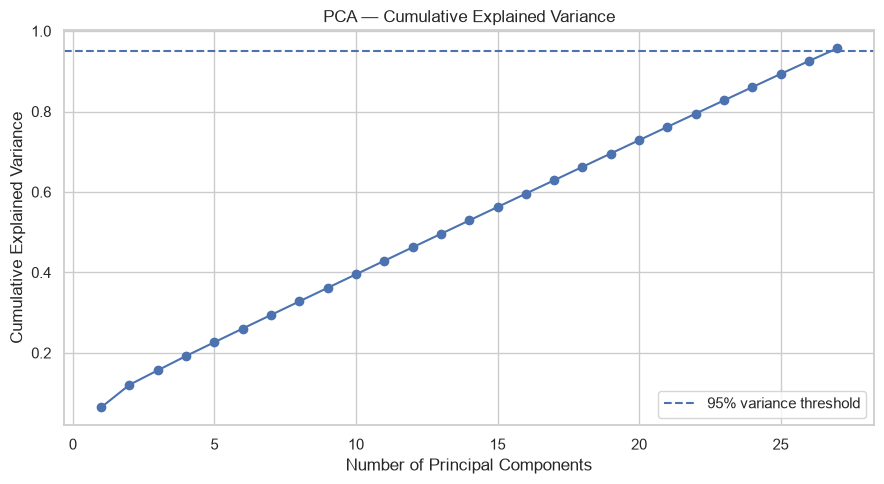

In [7]:
# Cell 8 — PCA explained variance

cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% variance threshold"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA — Cumulative Explained Variance")

plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "sfr_pca_explained_variance.png",
    dpi=300
)

plt.show()

In [8]:
# Cell 9 — Fattening through pairwise interactions

def generate_interactions(X):
    X = np.asarray(X)

    interaction_columns = []

    for i, j in combinations(range(X.shape[1]), 2):
        interaction_columns.append(X[:, i] * X[:, j])

    return np.column_stack(interaction_columns)


X_train_interactions = generate_interactions(X_train_slim)
X_val_interactions = generate_interactions(X_val_slim)

print("Training interaction features:", X_train_interactions.shape)
print("Validation interaction features:", X_val_interactions.shape)

Training interaction features: (182276, 351)
Validation interaction features: (45570, 351)


In [9]:
# Cell 10 — Combine slimmed and interaction features

X_train_refined = np.concatenate(
    [X_train_slim, X_train_interactions],
    axis=1
)

X_val_refined = np.concatenate(
    [X_val_slim, X_val_interactions],
    axis=1
)

print("Original features:", X_train.shape[1])
print("Slimmed features:", X_train_slim.shape[1])
print("Interaction features:", X_train_interactions.shape[1])

print("\nFinal refined training shape:", X_train_refined.shape)
print("Final refined validation shape:", X_val_refined.shape)

Original features: 30
Slimmed features: 27
Interaction features: 351

Final refined training shape: (182276, 378)
Final refined validation shape: (45570, 378)


In [10]:
# Cell 11 — Compare feature-space dimensions

feature_comparison = pd.DataFrame({
    "Representation": [
        "Original",
        "Slimmed",
        "Refined"
    ],
    "Number of Features": [
        X_train.shape[1],
        X_train_slim.shape[1],
        X_train_refined.shape[1]
    ]
})

display(feature_comparison)

,Representation,Number of Features
0,Original,30
1,Slimmed,27
2,Refined,378


In [11]:
# Cell 12 — Save the SFR feature views

np.save(SFR_DIR / "X_train_slim.npy", X_train_slim)
np.save(SFR_DIR / "X_val_slim.npy", X_val_slim)

np.save(SFR_DIR / "X_train_refined.npy", X_train_refined)
np.save(SFR_DIR / "X_val_refined.npy", X_val_refined)

joblib.dump(scaler, SFR_DIR / "scaler.joblib")
joblib.dump(pca, SFR_DIR / "pca.joblib")

print("SFR representations and transformations saved.")

SFR representations and transformations saved.


In [12]:
# Cell 13 — Train Random Forest on refined features

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    precision_score,
    recall_score
)
import time

sfr_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

start = time.time()

sfr_rf.fit(X_train_refined, y_train)

sfr_training_time = time.time() - start

print("SFR Random Forest training completed.")
print("Training time:", round(sfr_training_time, 2), "seconds")

SFR Random Forest training completed.
Training time: 173.83 seconds


In [13]:
# Cell 14 — Evaluate refined representation

sfr_predictions = sfr_rf.predict(X_val_refined)

sfr_results = {
    "Model": "SFR + Random Forest",
    "Macro F1": f1_score(
        y_val, sfr_predictions,
        average="macro",
        zero_division=0
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_val, sfr_predictions
    ),
    "Fraud Precision": precision_score(
        y_val, sfr_predictions,
        zero_division=0
    ),
    "Fraud Recall": recall_score(
        y_val, sfr_predictions,
        zero_division=0
    ),
    "Fraud F1": f1_score(
        y_val, sfr_predictions,
        zero_division=0
    ),
    "Training Time (s)": sfr_training_time
}

display(pd.DataFrame([sfr_results]).round(4))

,Model,Macro F1,Balanced Accuracy,Fraud Precision,Fraud Recall,Fraud F1,Training Time (s)
0,SFR + Random Forest,0.8721,0.8227,0.8793,0.6456,0.7445,173.8276


In [15]:
# Cell 15A — Load baseline experiment results

BASELINE_RESULTS_PATH = (
    PROJECT_DIR / "reports" / "baseline_results.csv"
)

if not BASELINE_RESULTS_PATH.exists():
    raise FileNotFoundError(
        "Baseline results not found. "
        "Make sure Cell 12 in Notebook 04 was executed."
    )

baseline_results = pd.read_csv(BASELINE_RESULTS_PATH)

print("Baseline results loaded successfully.")
display(baseline_results.round(4))

Baseline results loaded successfully.


,Model,Accuracy,Macro F1,Balanced Accuracy,Fraud Precision,Fraud Recall,Fraud F1,Training Time (s)
0,Random Forest,0.9996,0.9361,0.9113,0.9286,0.8228,0.8725,47.5477
1,Voting Ensemble,0.9995,0.9294,0.9239,0.8701,0.8481,0.8590,48.2051
2,Decision Tree,0.9992,0.8795,0.8795,0.7595,0.7595,0.7595,6.6837
3,Linear SVM,0.9768,0.5554,0.9568,0.0656,0.9367,0.1226,1.1330


In [16]:
# Cell 15 — Compare baseline and SFR

baseline_rf = baseline_results[
    baseline_results["Model"] == "Random Forest"
].iloc[0]

comparison = pd.DataFrame([
    {
        "Representation": "Original features",
        "Macro F1": baseline_rf["Macro F1"],
        "Balanced Accuracy": baseline_rf["Balanced Accuracy"],
        "Fraud Recall": baseline_rf["Fraud Recall"]
    },
    {
        "Representation": "SFR refined features",
        "Macro F1": sfr_results["Macro F1"],
        "Balanced Accuracy": sfr_results["Balanced Accuracy"],
        "Fraud Recall": sfr_results["Fraud Recall"]
    }
])

display(comparison.round(4))

,Representation,Macro F1,Balanced Accuracy,Fraud Recall
0,Original features,0.9361,0.9113,0.8228
1,SFR refined features,0.8721,0.8227,0.6456


In [17]:
import os
import pandas as pd

sfr_comparison = pd.DataFrame([
    {
        "Model": "Baseline Random Forest",
        "Features": 30,
        "Macro F1": 0.9361,
        "Balanced Accuracy": 0.9113,
        "Fraud Precision": 0.9286,
        "Fraud Recall": 0.8228,
        "Fraud F1": 0.8725
    },
    {
        "Model": "SFR Adaptation",
        "Features": 378,
        "Macro F1": 0.8721,
        "Balanced Accuracy": 0.8227,
        "Fraud Precision": 0.8793,
        "Fraud Recall": 0.6456,
        "Fraud F1": 0.7445
    }
])

output_path = os.path.join(
    PROJECT_DIR,
    "reports",
    "sfr_comparison.csv"
)

sfr_comparison.to_csv(output_path, index=False)

display(sfr_comparison)

print("Saved:", output_path)

,Model,Features,Macro F1,Balanced Accuracy,Fraud Precision,Fraud Recall,Fraud F1
0,Baseline Random Forest,30,0.9361,0.9113,0.9286,0.8228,0.8725
1,SFR Adaptation,378,0.8721,0.8227,0.8793,0.6456,0.7445


Saved: ../reports/sfr_comparison.csv
